# 助詞で文を区切るやつ

2026/10/07-10

BCCWJ1 で句点「。」の直前に接続助詞がきている箇所の KWIC (`data/kwic-20337828.txt`) を読み込んで、どの接続助詞が多いか（レジスタ別に）見てみる。

## 0. データ読み込み

In [142]:
import csv

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["font.family"] = "Hiragino Sans"

kwic_path = "../data/kwic-20337828.txt"
df = pd.read_csv(kwic_path, sep="\t", quoting=csv.QUOTE_NONE, dtype=str)
print(len(df))
df[["前文脈", "キー", "後文脈", "出版年"]].head()

46017


,前文脈,キー,後文脈,出版年
0,の|だ|。#あからさま|な|実名|報道|、|いかに|も|いかがわしく|しつらえ|られ|た|印...,て,|(。)#それ|を|つくら|れ|た|“|像|”|で|ある|と|対象|化|する|読者|は|、|...,1986
1,だけ|で|“|殺さ|れ|て|も|仕方|が|ない|（|存在|）|”|と|きめつけ|て|いる|の|だ|,から,|(。)#許せ|ない|の|は|この|記事|の|末尾|に|ある|、|笹川|氏|の|恋人|と|の...,1986
2,斥ける|でしょう|。#お|化け|みたい|じゃ|なく|たって|いい|ん|だ|。#ぼく|は|お|...,から,|(。)# |文字|に|なれる|こと|は|、|誰|で|も|知っ|て|い|ます|。#仰向け|に...,1986
3,もちろん|物語|の|なか|の|青空|で|あり|、|わたし|は|それ|を|読ん|だ|に|すぎ|...,から,|(。)#と|すれ|ば|、|わたし|は|ここ|で|噓|を|つい|て|いる|の|です|が|、|...,1986
4,て|かんがえ|たい|。#ジェスチュア|と|いう|より|は|、|むしろ|ライフスタイル|と|い...,て,|(。)#身|の|ふり|かた|と|身|の|こなし|の|あいだ|に|、|はっきり|と|で|て|...,1986


In [143]:
def read_count(path, index_col):
    """中納言の件数を書き留めたファイルを、件数の Series にする"""
    df_count = pd.read_csv(path, sep="\t", quoting=csv.QUOTE_NONE, dtype=str)
    return df_count.set_index(index_col)["件数"].str.replace(",", "").str.strip().astype(int)


# 句点「。」の直前の語の品詞 (大分類) と、助詞の場合の中分類
count_hinshi = read_count("../data/bccwj1_maru-kuten_zempo1-hinshi.txt", "品詞の大分類")
count_joshi = read_count("../data/bccwj1_maru-kuten_zempo1-joshi.txt", "品詞の中分類")
count_joshi.index = count_joshi.index.str.replace("助詞-", "")

count_kuten_total = 4_018_225

# 合計が合うか確かめる: 品詞の合計 = 句点の件数 (4,018,225)、助詞の中分類の合計 = 助詞、接続助詞 = KWIC の行数
print(f"品詞の合計 {count_hinshi.sum():,} / 句点 {count_kuten_total:,}")
print(f"助詞 {count_hinshi['助詞']:,} / 中分類の合計 {count_joshi.sum():,}")
print(f"接続助詞 {count_joshi['接続助詞']:,} / KWIC {len(df):,}")

品詞の合計 4,015,256 / 句点 4,018,225
助詞 417,994 / 中分類の合計 417,994
接続助詞 46,017 / KWIC 46,017


## 1. 句点「。」の直前の接続助詞 内訳

In [144]:
count_key = df["キー"].value_counts()
count_key.head(10)

キー
から     11622
が      10413
て       9884
けど      5156
し       5130
ば        949
で        729
けれど      608
ながら      421
と        376
Name: count, dtype: int64

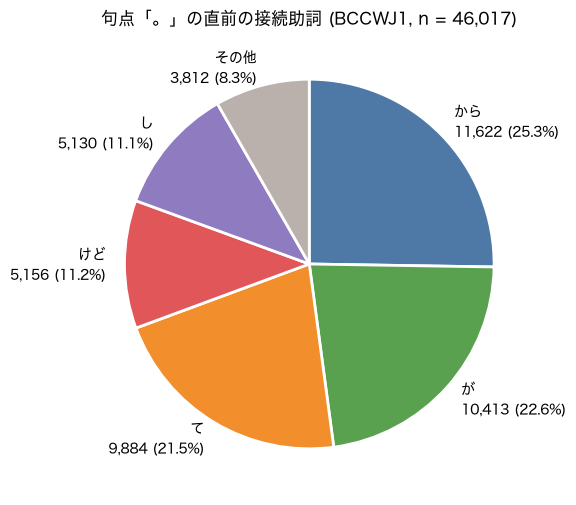

In [145]:
# 上位だけ残して、あとは「その他」にまとめる
top_n = 5
count_pie = count_key.head(top_n).copy()
count_pie["その他"] = count_key.iloc[top_n:].sum()

total = count_pie.sum()
labels = [f"{key}\n{count:,} ({count / total:.1%})" for key, count in count_pie.items()]
colors = ["#4e79a7", "#59a14f", "#f28e2b", "#e15759", "#8f7cc0", "#bab0ac"]


fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    count_pie,
    labels=labels,
    colors=colors,
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)
ax.set_title(f"句点「。」の直前の接続助詞 (BCCWJ1, n = {total:,})")
#plt.savefig("figs/20261007_te.png")
plt.show()

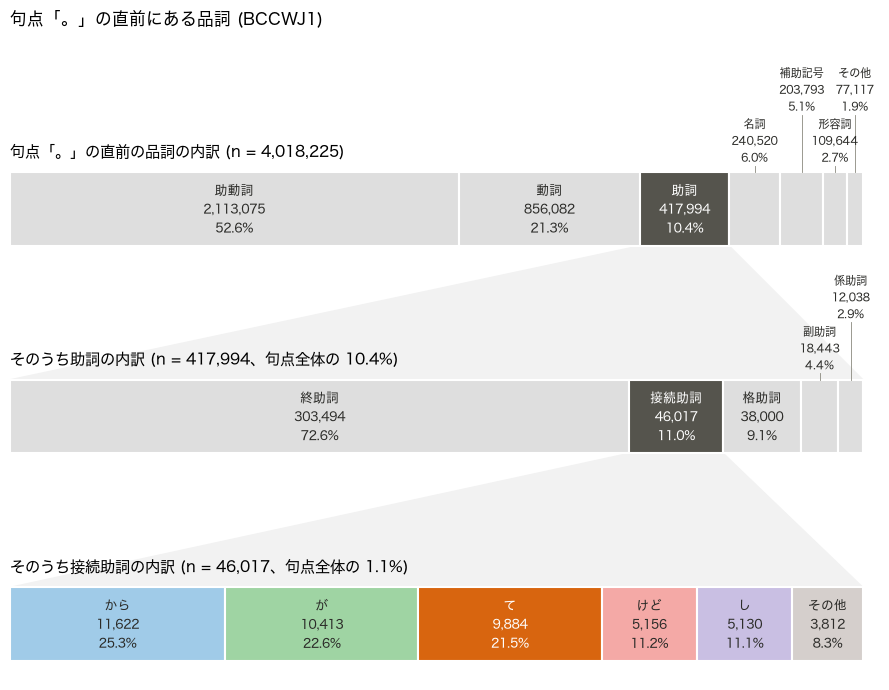

In [146]:
# 帯グラフを 3 段にして、上の段の一部を下の段で拡大していく
from matplotlib.colors import to_rgb

INK = "#2b2b28"
colors_hl = ["#a0cbe8", "#9fd4a3", "#d8650f", "#f4a9a6", "#c9bfe3", "#d5cfcc"]

def fold_small(count, min_share=0.02):
    """割合の小さい項目を「その他」にまとめて、多い順に並べる"""
    count = count.sort_values(ascending=False)
    small = count / count.sum() < min_share
    folded = count[~small].copy()
    if small.any():
        folded["その他"] = count[small].sum()
    return folded


def draw_band(ax, y, count, title, focus=None, band_colors=None, whole=None, height=0.46):
    """100% の帯を 1 本描く。focus の項目の左端と右端 (%) を返す

    focus の項目は濃い塗りに白い文字、ほかは薄い塗りに黒い文字にする
    whole を渡すと、この帯の合計が whole の何 % かをタイトルに添える
    """
    share = count / count.sum() * 100
    left = 0.0
    focus_range = None
    n_narrow = 0
    top = y + height / 2
    note = f"n = {count.sum():,}"
    if whole is not None:
        note += f"、句点全体の {count.sum() / whole:.1%}"
    ax.text(0, top + 0.08, f"{title} ({note})", fontsize=11, va="bottom")
    for i, (name, value) in enumerate(share.items()):
        if band_colors is not None:
            color = band_colors[i]
        else:
            color = "#55544d" if name == focus else "#dedede"
        text_color = "white" if name == focus else INK
        ax.barh(y, value, left=left, height=height, color=color, edgecolor="white", linewidth=1.5)
        center = left + value / 2
        label = f"{name}\n{count[name]:,}\n{value:.1f}%"
        if value >= 6.5:
            ax.text(center, y, label, ha="center", va="center", fontsize=9, color=text_color)
        elif value >= 0.5:
            # 幅の狭い項目は帯の上に、重ならないよう高さを交互に変えて書く
            lift = 0.04 + 0.32 * (n_narrow % 2)
            ax.plot([center, center], [top, top + lift], color="#8a897f", linewidth=0.6)
            ax.text(center, top + lift, label, ha="center", va="bottom", fontsize=8, color=INK)
            n_narrow += 1
        if name == focus:
            focus_range = (left, left + value)
        left += value
    return focus_range


def draw_zoom(ax, y_upper, y_lower, focus_range, height=0.46):
    """上の段の focus の範囲から、下の段の全体へ広がる帯を描く"""
    x0, x1 = focus_range
    top, bottom = y_upper - height / 2, y_lower + height / 2
    ax.fill([x0, x1, 100, 0], [top, top, bottom, bottom], color="#f2f2f2", zorder=0)


# 品詞の合計が句点の件数に足りない分は「不明」として足す (「その他」に入る)
count_hinshi_all = count_hinshi.copy()
count_hinshi_all["不明"] = count_kuten_total - count_hinshi.sum()

y_hinshi, y_joshi, y_setsuzoku = 2.6, 1.3, 0
fig, ax = plt.subplots(figsize=(9, 7))
range_joshi = draw_band(ax, y_hinshi, fold_small(count_hinshi_all), "句点「。」の直前の品詞の内訳", focus="助詞")
range_setsuzoku = draw_band(ax, y_joshi, fold_small(count_joshi), "そのうち助詞の内訳", focus="接続助詞", whole=count_kuten_total)
draw_band(ax, y_setsuzoku, count_pie, "そのうち接続助詞の内訳", focus="て", band_colors=colors_hl, whole=count_kuten_total)
draw_zoom(ax, y_hinshi, y_joshi, range_joshi)
draw_zoom(ax, y_joshi, y_setsuzoku, range_setsuzoku)

ax.set_xlim(0, 102)
ax.set_ylim(-0.35, 3.7)
ax.axis("off")
ax.set_title("句点「。」の直前にある品詞 (BCCWJ1)", loc="left")
fig.tight_layout()
plt.savefig("figs/20261007_te_band.png")
plt.show()

## 2. レジスターごとの割合（分母は句点「。」）

分母はレジスターごとの句点「。」の件数 (`data/bccwj1_maru-kuten_register.txt`)

In [147]:
kuten_path = "../data/bccwj1_maru-kuten_register.txt"
df_kuten = pd.read_csv(kuten_path, sep="\t", dtype=str)
count_kuten = (
    df_kuten.set_index("レジスター")["件数"].str.replace(",", "").str.strip().astype(int)
)

# 合計が全体の句点の件数 (4,018,225) と合うか確かめる
print(f"{count_kuten.sum():,}")
count_kuten

4,018,225


レジスター
出版・新聞            54459
出版・雑誌           184503
出版・書籍          1069047
図書館・書籍         1258202
特定目的・白書          97169
特定目的・ベストセラー     167140
特定目的・知恵袋        495218
特定目的・ブログ        418026
特定目的・法律          23026
特定目的・国会会議録      116686
特定目的・広報紙         93175
特定目的・教科書         40212
特定目的・韻文           1362
Name: 件数, dtype: int64

In [148]:
top_keys = list(count_key.head(top_n).index)
key_grouped = df["キー"].where(df["キー"].isin(top_keys), "その他")
count_register = pd.crosstab(df["レジスター"], key_grouped)[top_keys + ["その他"]]
count_register = count_register.reindex(count_kuten.index, fill_value=0)
count_register["計"] = count_register.sum(axis=1)

# 句点で終わる文のうち、接続助詞で終わっているものの割合 (%)
print("句点で終わる文のうち、接続助詞で終わっている割合 (%)")
rate_register = count_register.div(count_kuten, axis=0) * 100
rate_register["句点"] = count_kuten
rate_register.sort_values("計", ascending=False).round(2)

句点で終わる文のうち、接続助詞で終わっている割合 (%)


キー,から,が,て,けど,し,その他,計,句点
レジスター,,,,,,,,
特定目的・知恵袋,0.54,1.05,0.26,0.34,0.44,0.07,2.69,495218
特定目的・ブログ,0.29,0.49,0.46,0.40,0.37,0.18,2.19,418026
特定目的・韻文,0.29,0.15,0.81,0.00,0.00,0.44,1.69,1362
出版・雑誌,0.29,0.09,0.60,0.10,0.10,0.09,1.27,184503
特定目的・国会会議録,0.36,0.21,0.17,0.00,0.01,0.18,0.93,116686
特定目的・ベストセラー,0.31,0.10,0.20,0.06,0.05,0.10,0.83,167140
図書館・書籍,0.28,0.12,0.21,0.07,0.05,0.09,0.81,1258202
出版・書籍,0.25,0.10,0.22,0.06,0.05,0.09,0.76,1069047
特定目的・教科書,0.06,0.01,0.17,0.01,0.00,0.04,0.29,40212


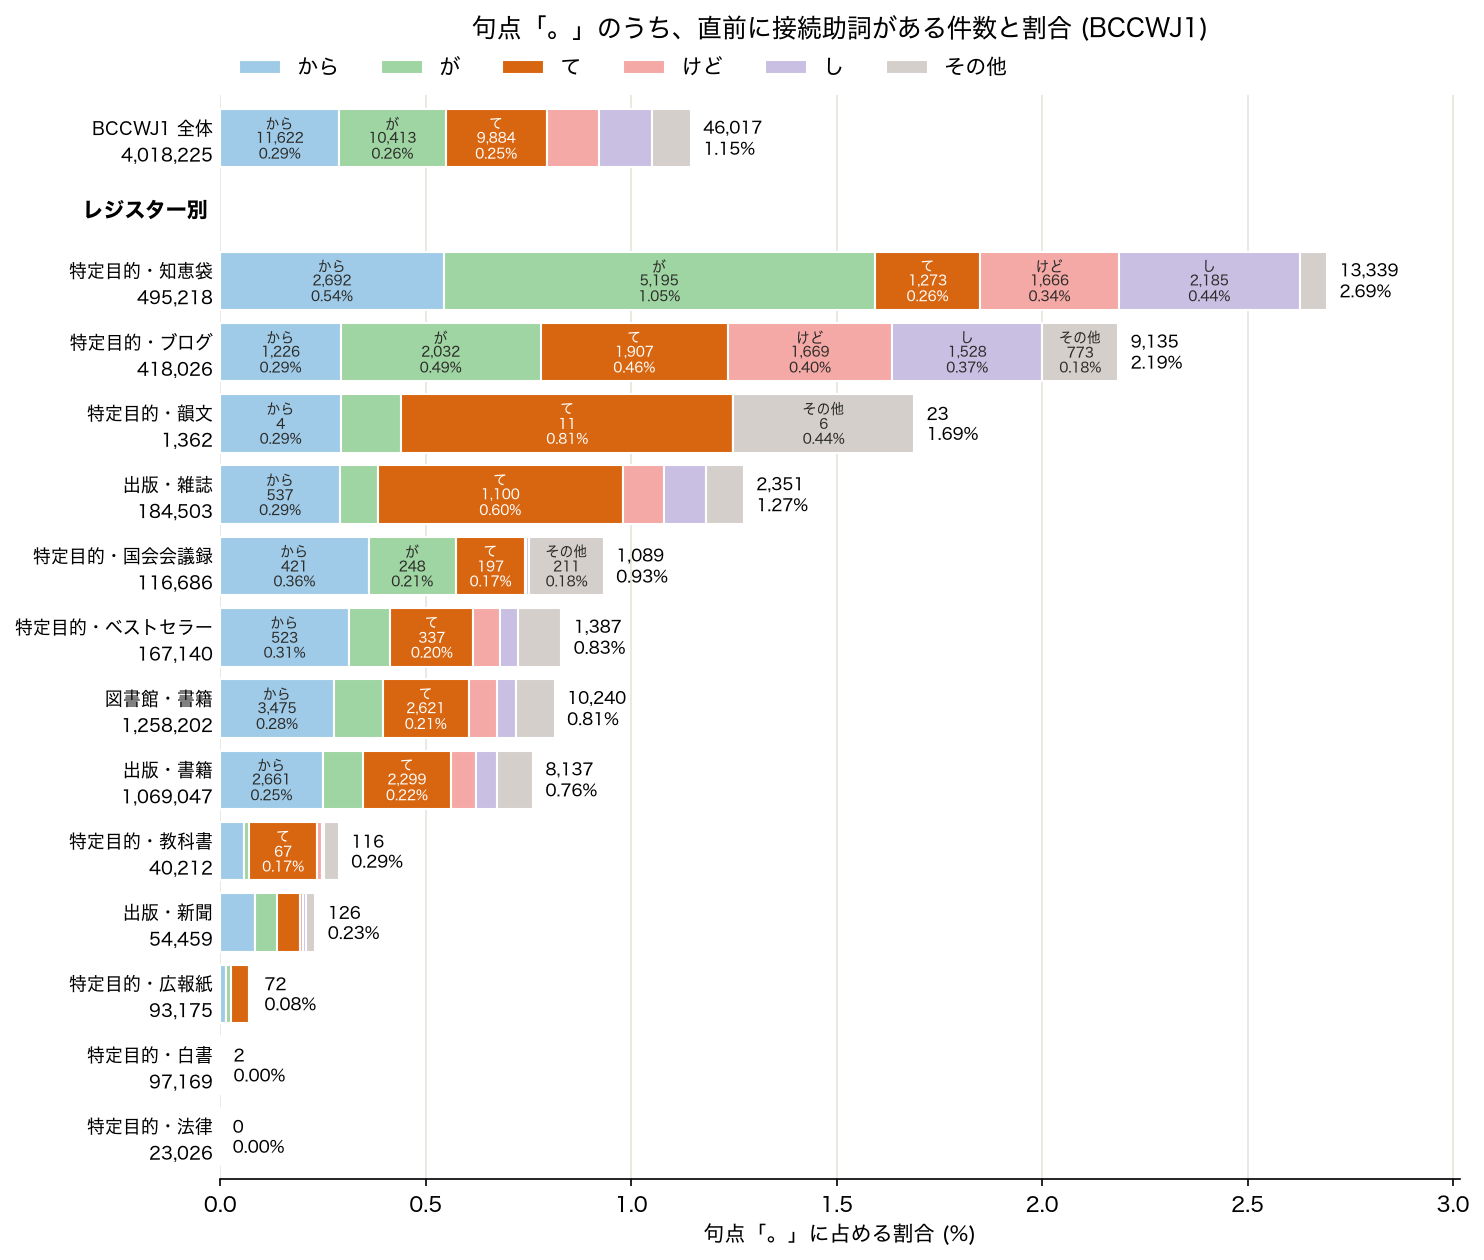

In [149]:
# 横棒の長さ = 直前に接続助詞がある割合の計、色分け = どの接続助詞か
from matplotlib.colors import to_rgb


def text_color_on(color):
    """塗りの上で読みやすいほうの文字色 (白か黒) を返す"""
    r, g, b = [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in to_rgb(color)]
    luminance = 0.2126 * r + 0.7152 * g + 0.0722 * b
    return "white" if luminance < 0.3 else "#2b2b28"


keys_plot = top_keys + ["その他"]
rate_plot = rate_register.sort_values("計")[keys_plot]
count_plot = count_register.loc[rate_plot.index, keys_plot]
kuten_plot = count_kuten[rate_plot.index]

# いちばん上に BCCWJ1 全体を足す (帯グラフの「句点全体の 1.1%」と同じ数字)
count_plot.loc["BCCWJ1 全体"] = count_plot.sum()
kuten_plot["BCCWJ1 全体"] = kuten_plot.sum()
rate_plot.loc["BCCWJ1 全体"] = count_plot.loc["BCCWJ1 全体"] / kuten_plot["BCCWJ1 全体"] * 100

# レジスターは下から 0, 1, 2, ...、1 行あけて (小見出し「レジスター別」を置く)、いちばん上に全体
n_register = len(rate_plot) - 1
y = list(range(n_register)) + [n_register + 1]
min_width = 0.15  # これより幅の狭い帯には文字を入れない

fig, ax = plt.subplots(figsize=(10, 8.5), dpi=150)
left = pd.Series(0.0, index=rate_plot.index)
for key, color in zip(keys_plot, colors_hl):
    ax.barh(y, rate_plot[key], left=left, height=0.82, color=color, edgecolor="white", linewidth=1, label=key)
    for y_bar, register in zip(y, rate_plot.index):
        rate = rate_plot.loc[register, key]
        if rate >= min_width:
            label = f"{key}\n{count_plot.loc[register, key]:,}\n{rate:.2f}%"
            ax.text(left[register] + rate / 2, y_bar, label, ha="center", va="center",
                    fontsize=6.5, linespacing=1.1, color=text_color_on(color))
    left += rate_plot[key]
# 棒の右に、直前に接続助詞がある句点の件数と割合 (計)
for y_bar, register in zip(y, rate_plot.index):
    total_text = f"{count_plot.loc[register].sum():,}\n{left[register]:.2f}%"
    ax.text(left[register] + 0.03, y_bar, total_text, va="center", fontsize=8, linespacing=1.2)

# レジスター名の下に、分母になる句点の件数
ax.set_yticks(y, [f"{register}\n{kuten_plot[register]:,}" for register in rate_plot.index], fontsize=8.5)
ax.text(-0.01, n_register, "レジスター別", transform=ax.get_yaxis_transform(), ha="right", va="center", fontweight="bold")
ax.set_xlim(0, left.max() * 1.12)
ax.set_ylim(-0.6, n_register + 1.6)
ax.set_xlabel("句点「。」に占める割合 (%)")
ax.set_title("句点「。」のうち、直前に接続助詞がある件数と割合 (BCCWJ1)", pad=28)
ax.legend(ncols=6, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False)
ax.grid(axis="x", color="#e5e4dc", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
plt.savefig("figs/20261007_te_register.png", dpi=200)
plt.show()

✏️メモ

- 句点で終わる文のうち、直前に接続助詞がある割合
    - 高いのは、知恵袋・ブログ・韻文・雑誌
    - 低い（ない）のは、法律・白書・広報紙・新聞
- 接続助詞別
    - `から`: 「知恵袋」で多く (0.54%)、  
    国会会議録・ベストセラー・ブログ・韻文・雑誌・書籍 (0.25-0.36%) でも多い
    - `が`: 知恵袋 (1.05%) ・ブログ (0.49%) で多い
    - `て`: 雑誌 (0.60%)、ブログ (0.46%) で多い
        - 韻文 (0.81%) でも多いが事例数としては少ない (11件)
        - **雑誌**では書籍（0.21〜0.22%）の2〜3倍。雑誌では「から」の倍ある。

韻文の 23 件（接続助詞）は、詩。

> ものを見守る視線の作るいくつかの交点を通るとき風はちょっと燃焼する、つぎつぎと軽い音を立て	て	(。)ガットに当るボールのふしぎな音のように。  
*OV2X_00005 衣更着信詩集	衣更着信	思潮社	1987*

雑誌にはアドバイスやインタビュー書き起こしがある。

アドバイス（依頼表現）
> シンプルな分、野菜の下ごしらえで味が決まるんです。今まで手を抜いていた野菜の下ごしらえを、少しだけていねいにしてみ	て	(。)「サラダがいつもと違う」と感じるはずです。  
*PM21_00369	相沢　ひろみ(著)/逆瀬川　由夏(著)	女性セブン		小学館	2002*

インタビュー（理由）
> 那和　僕もペンタックスＳＰ買ったのは、ニコンＦが買えなかったからですよ、当時お金がなく	て	(。)萩谷　私はこのリストの中では、ミノルタオートコードがいいなと思いますね。  
*PM11_00234	アサヒカメラ編集部(著)/河田　一規(著)/竹中　隆義(著)/萩谷　剛(著)/赤城　耕一(著)/那和　秀峻(著)	アサヒカメラ		朝日新聞社	2001*

## 3. 「て」の直前の語

`前文脈` は `|` で語に区切られているので、最後の語を取り出して数える

In [150]:
df_te = df[df["キー"] == "て"].copy()
df_te["直前の語"] = df_te["前文脈"].str.rstrip("|").str.split("|").str[-1]
count_prev = df_te["直前の語"].value_counts()
print(len(df_te), len(count_prev))
count_prev.head(10)

9884 1185


直前の語
し      1433
まし      482
なく      439
つい      379
み       294
思っ      274
ちゃっ     245
い       208
なっ      200
て       184
Name: count, dtype: int64

In [151]:
# 上位の語をレジスター別に数える
top_prev = list(count_prev.head(15).index)
count_prev_register = pd.crosstab(df_te["直前の語"], df_te["レジスター"]).loc[top_prev]
count_prev_register["計"] = count_prev_register.sum(axis=1)
count_prev_register

レジスター,出版・新聞,出版・書籍,出版・雑誌,図書館・書籍,特定目的・ブログ,特定目的・ベストセラー,特定目的・国会会議録,特定目的・広報紙,特定目的・教科書,特定目的・白書,特定目的・知恵袋,特定目的・韻文,計
直前の語,,,,,,,,,,,,,
し,2,316,170,361,278,57,44,7,11,0,186,1,1433
まし,1,66,25,81,171,13,19,0,1,0,105,0,482
なく,2,100,21,112,81,7,6,0,1,0,109,0,439
つい,6,65,15,74,49,3,28,17,0,1,121,0,379
み,0,58,75,43,50,4,0,0,1,0,63,0,294
思っ,1,57,32,77,52,15,0,0,1,0,39,0,274
ちゃっ,0,65,18,88,51,6,0,0,1,0,16,0,245
い,0,70,8,43,59,4,1,0,0,0,23,0,208
なっ,1,51,16,63,34,5,3,0,7,0,19,1,200


### 3.1 「いて。」

In [152]:
def show_examples(prev, n=30, register=None, seed=0):
    """「prev + て。」の例を n 件、ランダムに取り出して表示する"""
    rows = df_te[df_te["直前の語"] == prev]
    if register is not None:
        rows = rows[rows["レジスター"] == register]
    print(f"{prev}て。 {len(rows)} 件")
    for _, row in rows.sample(min(n, len(rows)), random_state=seed).iterrows():
        context = row["前文脈"].replace("|", "")[-40:]
        print(f"{row['レジスター']}\t{context}【て】。")


show_examples("い")

いて。 208 件
図書館・書籍	いかなかった。#　みんなは私の知らない何かについて喋り続けてい【て】。
特定目的・ブログ	が設立されたと記述あり。#さらに、広報も活動の一環と捉えてい【て】。
図書館・書籍	いたから、つらいこと、悲しいことをいやっていうほど経験してきてい【て】。
図書館・書籍	病気や。#春までには、ちゃんとようなってみせるさけ、心配せんとい【て】。
出版・書籍	の声。#迅雷の背後に、桓魋たちの仲間。#桓魋ではなく柴望がい【て】。
特定目的・ブログ	いる。#そんなチヒョンに、#「いいから。#いいから。#ゲストは居間でくつろいでい【て】。
特定目的・ブログ	ても自分の命を犠牲にしても解決するからどうか安心してい【て】。
特定目的・ブログ	ために国際的なところでまっとうな貢献をするからどうか　安心してい【て】。
特定目的・ブログ	ために国際的なところでまっとうな貢献をするからどうか　安心してい【て】。
出版・書籍	。#一生懸命明るく振る舞っている、郷子。#将一と優は、淡々としてい【て】。
特定目的・ベストセラー	大切にしてあげよう。#愛ちん、もっとオレ、大人になるからずっと一緒にい【て】。
出版・書籍	」#「いやよ。#ね、話は応接間ですむから、このまま寝てい【て】。
特定目的・知恵袋	３チャンネル見れます。#画面の説明の端には「契約済み」と出てい【て】。
出版・書籍	■陽子の私室#向き合って会話する陽子と遠甫。#嬉しくお茶を出す玉葉がい【て】。
特定目的・ブログ	ために国際的なところでまっとうな貢献をするからどうか　安心してい【て】。
特定目的・ブログ	んですよね〜。#そしたら、彼氏後輩がなんだかしんみりしてい【て】。
出版・雑誌	ね。#そこら中に女口説いてる奴や、振られて泣いてる奴がい【て】。
図書館・書籍	見つめていた。#　稲葉にいった―もう消えないで、ずっとそばにい【て】。
特定目的・知恵袋	友達と一緒に始めます。#友達はずっと経験があるから、お客様はい【て】。
図書館・書籍	子の髪、こんなに伸びましたのよ。#それも、ゆっさりしてい【て】。
出版・書籍	ございます…でも、悪くないさ、恵達」#ステージ袖には、祥子がい【て】。
図書館・書籍	初夜」は日没後三、四時間の間。#十一　長い間倒れてい【て】。
図書館・書籍	だめよ、冬城、無理だわ。#あなたは『

<!--
```
図書館・書籍	いかなかった。#　みんなは私の知らない何かについて喋り続けてい【て】。	o
特定目的・ブログ	が設立されたと記述あり。#さらに、広報も活動の一環と捉えてい【て】。	o
図書館・書籍	いたから、つらいこと、悲しいことをいやっていうほど経験してきてい【て】。	o
図書館・書籍	病気や。#春までには、ちゃんとようなってみせるさけ、心配せんとい【て】。	x (依頼)
出版・書籍	の声。#迅雷の背後に、桓魋たちの仲間。#桓魋ではなく柴望がい【て】。	o
特定目的・ブログ	いる。#そんなチヒョンに、#「いいから。#いいから。#ゲストは居間でくつろいでい【て】。	o
特定目的・ブログ	ても自分の命を犠牲にしても解決するからどうか安心してい【て】。	x (依頼)
特定目的・ブログ	ために国際的なところでまっとうな貢献をするからどうか　安心してい【て】。	x (依頼)
特定目的・ブログ	ために国際的なところでまっとうな貢献をするからどうか　安心してい【て】。	x (依頼)
出版・書籍	。#一生懸命明るく振る舞っている、郷子。#将一と優は、淡々としてい【て】。	o
特定目的・ベストセラー	大切にしてあげよう。#愛ちん、もっとオレ、大人になるからずっと一緒にい【て】。	x (依頼)
出版・書籍	」#「いやよ。#ね、話は応接間ですむから、このまま寝てい【て】。	x (依頼)
特定目的・知恵袋	３チャンネル見れます。#画面の説明の端には「契約済み」と出てい【て】。	o
出版・書籍	■陽子の私室#向き合って会話する陽子と遠甫。#嬉しくお茶を出す玉葉がい【て】。	o
特定目的・ブログ	ために国際的なところでまっとうな貢献をするからどうか　安心してい【て】。	x (依頼)
特定目的・ブログ	んですよね〜。#そしたら、彼氏後輩がなんだかしんみりしてい【て】。	o
出版・雑誌	ね。#そこら中に女口説いてる奴や、振られて泣いてる奴がい【て】。	o
図書館・書籍	見つめていた。#　稲葉にいった―もう消えないで、ずっとそばにい【て】。	x (依頼)
特定目的・知恵袋	友達と一緒に始めます。#友達はずっと経験があるから、お客様はい【て】。	o
図書館・書籍	子の髪、こんなに伸びましたのよ。#それも、ゆっさりしてい【て】。	o
```
-->

上記「いて。」20件中、依頼 (8件) それ以外 (12件)

## 4. ノート

次にやりたいこと
- レジスターごとに30件ずつぐらいサンプリングして、依頼かそれ以外かに手で分類する
- 先行研究を調べる
    - 従属節のみを述べ主節を省略する（増岡・田窪『基礎日本語文法』）
    - テ形 副詞節: 原因、条件、手段、付帯状況、等（増岡・田窪『基礎日本語文法』）
    - （他にもあるのか？）